# Washington tire market opportunity (POC)

## 1. Question and answer

**Question:** which Washington counties have tire-dealer sales above what registered vehicles and dealership activity predict, and/or tire-dealer sales growing faster than dealer activity?

**Answer:** **Grant County** is the one robust candidate. Under both dealer measures, its real tire-dealer sales were above the out-of-sample expectation in every test year, by more than 2× the model's typical error (+30% in the primary dealer-employment view). Its tire sales also grew (+12%, 2019→2023) while new-car dealer employment fell (−16%).

**Kittitas and Jefferson** are flagged only when dealer activity is measured by dealer sales through 2025. Kittitas drops under the employment view because its tire growth came in 2024–25, after CBP's last year (2023). Jefferson has no CBP data.

These are **candidate markets to investigate, not proof** that dealerships are losing tire business to independents.


In [1]:
import pandas as pd
from IPython.display import Markdown
from wa_tire import config, plots, signals
from wa_tire.build import load_processed
pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.max_rows", 60)
pd.set_option("display.width", 200)

## 2. Data

This section shows where the numbers come from, what period they cover, and which counties were left out and why.

- **Tire and dealer sales:** WA Dept. of Revenue, Taxable Retail Sales (local) builder, retail sales tax, quarterly 2015Q1–2026Q1. Tire dealers = NAICS 441320 (to 2022Q1) + 441340 (from 2022Q2); new-car dealers = 441110. Cities and unincorporated areas are summed to counties; transit-area (PTBA) and empty `xx99` codes are dropped (`reports/location_codes.md`).
- **Dealer employment (primary dealer measure):** Census County Business Patterns, NAICS 441110, mid-March employment, 2017–2023. Small counties are not published.
- **Demand:** WA Dept. of Licensing registration transactions, Passenger Vehicle + Truck, by owner's county, 2017–2025 (data.wa.gov `hmzg-s6q4`).
- **Prices:** BLS CPI-U Tires (`CUUR0000SETC01`) for tire sales and New vehicles (`CUUR0000SETA01`) for dealer sales; constant 2025 dollars.
- **Exclusions:** a county-quarter counts as hidden when suppressed cells could hold more than 25% of tire-dealer taxpayers. Counties hidden in more than 25% of quarters are excluded from all views. Each view also drops counties that lack its dealer measure in any model year.

In [2]:
coverage = load_processed("coverage")
coverage.loc[coverage["excluded"], ["county", "hidden_quarter_share", "reason"]]

,county,hidden_quarter_share,reason
6,Columbia,0.467,tire data hidden in 47% of quarters
8,Douglas,0.356,tire data hidden in 36% of quarters
11,Garfield,0.622,tire data hidden in 62% of quarters; a model y...
13,Grays Harbor,0.333,tire data hidden in 33% of quarters
21,Lincoln,0.778,tire data hidden in 78% of quarters
24,Pacific,0.533,tire data hidden in 53% of quarters
25,Pend Oreille,0.556,tire data hidden in 56% of quarters
29,Skamania,0.733,tire data hidden in 73% of quarters
34,Wahkiakum,0.511,tire data hidden in 51% of quarters
37,Whitman,0.911,tire data hidden in 91% of quarters


In [3]:
load_processed("view_summary")

,view,measure,model_years,test_years,counties,dropped_no_dealer_data,top_candidates
0,cbp_emp,New-car dealer employment (CBP),2017-2023,2022-2023,20,"Adams, Asotin, Ferry, Island, Jefferson, Klick...",Grant
1,sales,New-car dealer real taxable sales (DOR),2017-2025,2022-2025,29,NaN,"Jefferson, Kittitas, Grant"


## 3. Exploration

This chart shows statewide real taxable sales for tire dealers and new-car dealers, each indexed to its 2019 average.

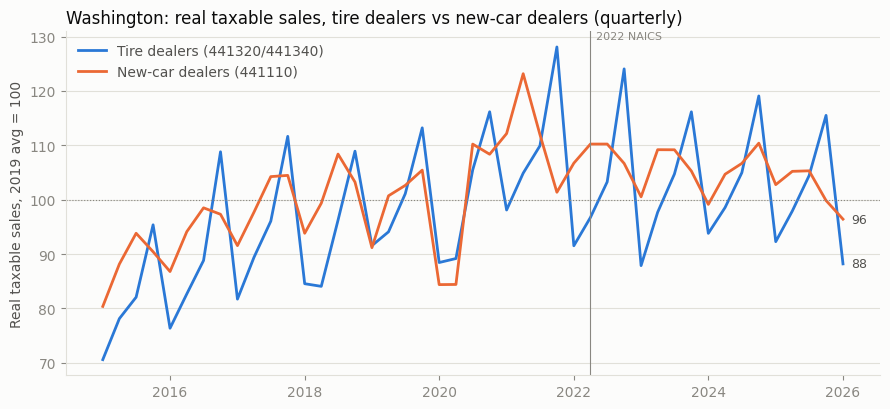

In [4]:
cq = load_processed("county_quarter")
plots.statewide_index(cq);

## 4. Model

This section shows how expected tire-shop sales are estimated for each county.

- **Baseline:** real tire-dealer sales per registered vehicle × county vehicles.
- **Model:** OLS of log real tire-dealer sales on log vehicles and log dealer activity, with year effects (standard errors clustered by county).
- **Dealer activity** is CBP new-car dealer employment (primary view) or DOR real new-car-dealer sales (secondary view).
- **Split:** train 2017–2021; test 2022–2023 (CBP view) or 2022–2025 (sales view).
- **Calibration:** both methods are scaled each year to the actual total of the counties in the view, so the test measures how well each method *allocates* sales across counties.

In [5]:
load_processed("coefficients_cbp_emp")

,term,coef,std_err (cluster by county),p_value,n_obs,r_squared
0,log_vehicles,0.652,0.163,0.000,100,0.955
1,log_dealer,0.148,0.142,0.298,100,0.955


In [6]:
load_processed("coefficients_sales")

,term,coef,std_err (cluster by county),p_value,n_obs,r_squared
0,log_vehicles,0.398,0.213,0.062,145,0.821
1,log_dealer,0.348,0.165,0.035,145,0.821


## 5. Evaluation

These tables compare baseline and model errors on the test years for each view (MAPE = mean absolute percentage error).

In [7]:
load_processed("evaluation_cbp_emp")

,method,MAPE,mean_abs_log_error,n_county_years,years
0,baseline,0.207,0.237,40,2022-2023
1,model,0.137,0.132,40,2022-2023


In [8]:
load_processed("evaluation_sales")

,method,MAPE,mean_abs_log_error,n_county_years,years
0,baseline,0.774,0.358,116,2022-2025
1,model,0.435,0.305,116,2022-2025


## 6. Results

This section ranks counties on both signals, shows which counties are flagged under each dealer measure, and lists hypotheses other than dealer loss.

- **Residual flag:** actual above the out-of-sample expectation in every recent test year, *and* the mean recent log residual is more than 1× the model's typical error (median absolute test log error). `residual_z` is that ratio.
- **Growth flag:** top quartile on the relative growth gap, with the gap > 0 and real tire growth > 0. The relative gap is (county − state tire growth) − (county − state dealer growth), 2019→last year of the view. It ranks counties exactly like the raw gap; only the zero line moves.
- **Top candidate:** both flags.

### Primary view: CBP dealer employment

In [9]:
ranked = load_processed("signals_cbp_emp")
ranked[["county", "test_years_above", "test_years", "residual_pct", "residual_z", "tire_growth_log", "dealer_growth_log", "relative_gap_log", "residual_flag", "growth_flag", "top_candidate"]]

,county,test_years_above,test_years,residual_pct,residual_z,tire_growth_log,dealer_growth_log,relative_gap_log,residual_flag,growth_flag,top_candidate
0,Grant,2,2,0.300,2.366,0.110,-0.170,0.171,True,True,True
1,Chelan,2,2,0.052,0.453,0.027,-0.483,0.399,False,True,False
2,Franklin,2,2,0.278,2.211,0.068,-0.154,0.112,True,False,False
3,Yakima,2,2,0.036,0.317,0.096,-0.211,0.197,False,True,False
4,Snohomish,2,2,0.040,0.354,0.002,-0.131,0.023,False,False,False
5,Okanogan,2,2,0.051,0.447,0.051,0.000,-0.059,False,False,False
6,Skagit,0,2,-0.098,-0.929,0.118,-0.181,0.190,False,True,False
7,Spokane,2,2,0.268,2.141,0.050,0.037,-0.097,True,False,False
8,Cowlitz,2,2,0.049,0.430,0.067,0.041,-0.084,False,False,False
9,Pierce,2,2,0.020,0.175,0.018,-0.099,0.007,False,False,False


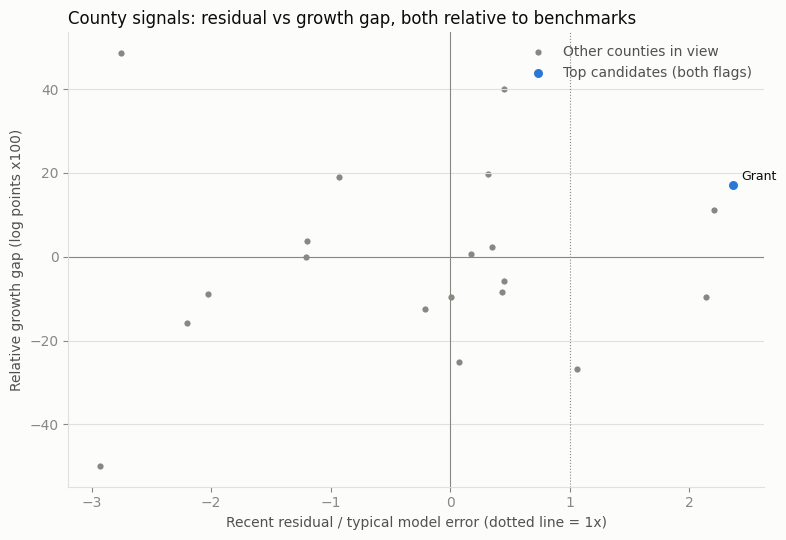

In [10]:
plots.signal_scatter(ranked, config.RESIDUAL_Z_MIN);

### Secondary view: dealer sales

In [11]:
ranked_sales = load_processed("signals_sales")
ranked_sales.loc[ranked_sales["residual_flag"] | ranked_sales["growth_flag"], ["county", "test_years_above", "test_years", "residual_pct", "residual_z", "tire_growth_log", "dealer_growth_log", "relative_gap_log", "residual_flag", "growth_flag", "top_candidate"]]

,county,test_years_above,test_years,residual_pct,residual_z,tire_growth_log,dealer_growth_log,relative_gap_log,residual_flag,growth_flag,top_candidate
0,Jefferson,4,4,0.673,2.925,0.026,-0.257,0.295,True,True,True
1,Kittitas,4,4,0.497,2.295,0.128,-0.332,0.472,True,True,True
2,Grant,4,4,0.495,2.286,0.085,-0.096,0.192,True,True,True
4,Island,2,4,0.080,0.438,0.050,-0.888,0.950,False,True,False
5,Adams,4,4,1.992,6.232,-0.052,-0.014,-0.026,True,False,False
6,Asotin,4,4,1.214,4.518,0.147,0.180,-0.021,True,False,False
7,Cowlitz,1,4,-0.106,-0.636,0.034,-0.458,0.504,False,True,False
10,Spokane,4,4,0.276,1.385,0.023,0.051,-0.016,True,False,False
12,Skagit,0,4,-0.115,-0.697,0.143,-0.077,0.232,False,True,False
14,Klickitat,4,4,0.933,3.747,-0.120,0.695,-0.803,True,False,False


### Do candidates change with the dealer measure?

In [12]:
comparison = load_processed("candidates_by_view")
comparison[comparison.filter(like="top_candidate").eq(True).any(axis=1)]

,county,residual_flag_cbp_emp,growth_flag_cbp_emp,top_candidate_cbp_emp,residual_flag_sales,growth_flag_sales,top_candidate_sales
0,Grant,True,True,True,True,True,True
12,Kittitas,True,False,False,True,True,True
20,Jefferson,NaN,NaN,NaN,True,True,True


### Plausible non-dealer explanations (hypotheses, untested)

Each flagged county could show a high or fast-growing tire-dealer signal for reasons that have nothing to do with dealerships losing tire business. These are **hypotheses** to check, not findings.

| County | Flagged in | Hypotheses other than dealer loss |
|---|---|---|
| Grant | both views | Agricultural and fleet buyers (farm trucks, implements, commercial tires) buying from tire dealers. Moses Lake as a regional retail hub drawing buyers from smaller neighbouring counties. I-90 through traffic. |
| Kittitas | dealer-sales view only | I-90 corridor traffic over Snoqualmie Pass (winter tire and chain demand, roadside replacements). Central Washington University students whose cars are registered elsewhere, so demand looks high relative to registrations. The 2024 tire jump could be a new store or a business reclassified into 441340. |
| Jefferson | dealer-sales view only | Small, volatile and often hidden: dealer sales are about $1M a year with frequent suppressed cells, so ratios swing. Residents may buy cars outside the county but service tires locally. |


In [13]:
flagged = signals.flagged_counties(comparison, ["cbp_emp", "sales"])
flagged

['Grant', 'Kittitas', 'Jefferson']

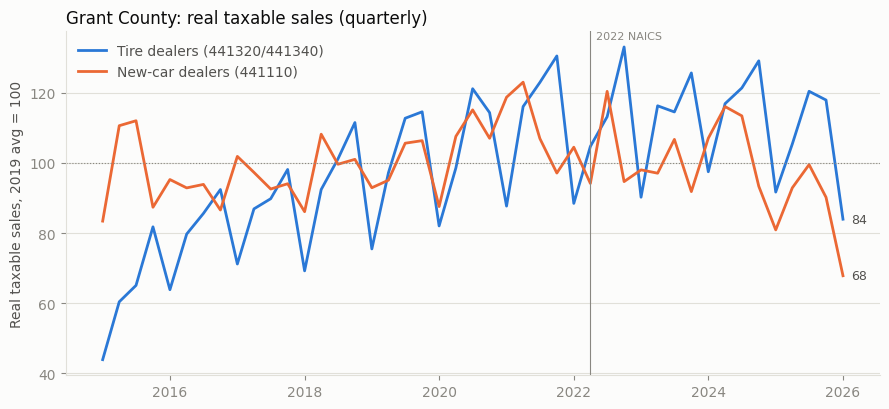

In [14]:
plots.county_index(cq, flagged[0]);

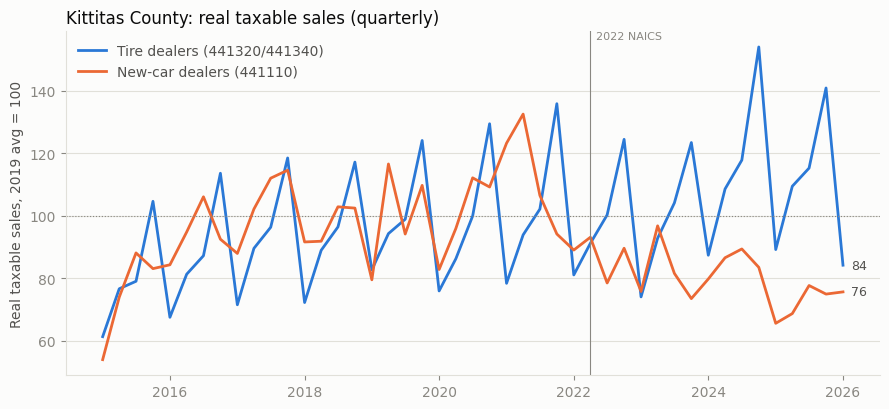

In [15]:
plots.county_index(cq, flagged[1]);

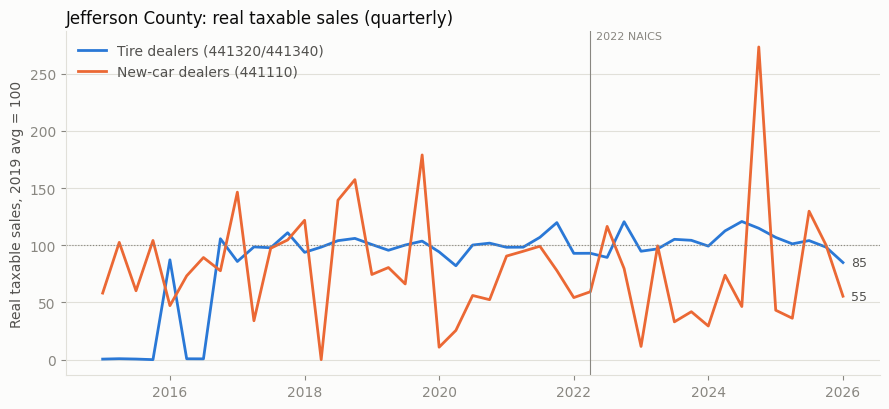

In [16]:
plots.county_index(cq, flagged[2]);

## 7. Caveats

This section lists what limits these results and what each limitation could change. It is the content of `CAVEATS.md`.

In [17]:
Markdown((config.ROOT / "CAVEATS.md").read_text())

# Caveats

The results are **candidate markets, not proof** that dealerships are losing tire business to independent tire shops. Each caveat below says what it could change.

| # | Caveat | What it could change |
|---|---|---|
| 1 | **One state.** Washington only, because it is the state found that publishes six-digit tire-dealer sales by county (see `reports/state_sales_check.md`). | Nothing here transfers to other states without equivalent data. Washington's tax rules (no income tax, destination sourcing) may make its pattern atypical. |
| 2 | **39 counties, fewer modelled.** Ten small counties are excluded for tire-data suppression (`exclusions.csv`), leaving 29. The primary CBP view also drops 9 counties where CBP does not publish new-car dealer employment in every year 2017–2023: Adams, Asotin, Ferry, Island, Jefferson, Klickitat, Mason, San Juan, Stevens. That leaves **20 counties**. | The regression is small-sample (100 county-years in the CBP view). Rankings and flags move when counties are added or dropped. Jefferson, a top candidate under dealer sales, cannot be assessed in the CBP view at all. |
| 3 | **Taxable sales only.** DOR reports sales subject to local retail sales tax. Sales to tax-exempt buyers, resale and out-of-state deliveries are excluded. | Counties where tire dealers sell heavily to exempt buyers (government fleets, farms, resellers) look smaller than they are, which biases their residual down. |
| 4 | **Hidden ("D") cells.** Cells with fewer than 3 taxpayers are suppressed. County totals are sums of *disclosed* cells, so they are lower bounds. Each hidden cell holds 1–2 taxpayers. | Counties with many small towns understate their sales. A change in suppression over time (a town crossing 3 shops) can create artificial growth. Hidden counts per county-quarter are in `county_quarter.csv` (`hidden_cells`, `hidden_share_ub`). |
| 5 | **Dealer tire sales cannot be separated.** New-car dealers (441110) report one taxable-sales total covering vehicles, parts, service and tires. Dealer sales therefore **mostly reflect new-car sales, which fell nationally after 2019** (pandemic and semiconductor-shortage supply limits). CBP dealer employment is the primary measure partly for this reason; dealer sales are kept as a secondary view. | Under dealer sales, a positive growth gap mostly means car sales fell, not that tire shops gained share of dealers' tire business. Employment is less sensitive to vehicle prices and inventory, but it still measures the whole dealership, not its tire department. |
| 6 | **Big-box, warehouse-club and online sellers are not captured.** Costco, Walmart and online tire sales are classified outside 441320/441340 (e.g. 455 general merchandise, or remote sellers). | Counties where those channels are strong look under-served by tire shops (negative residual) when demand is being met elsewhere. The analysis cannot see where dealers' tire customers actually go. |
| 7 | **Demand is estimated from registrations.** These are DOL registration *transactions* for Passenger Vehicle + Truck by owner's county and calendar year. Annual renewal makes this approximate the fleet, but multi-transaction vehicles and fleet registrations add noise. DOL monthly data start January 2017, so **modelling runs from 2017, not 2015** (train 2017–2021; test 2022–2025 in the dealer-sales view, 2022–2023 in the CBP view). | Vehicle-mix differences (trucks vs cars, studded-tire use in the east) are not in the model. The training period is two years shorter than specified. |
| 8 | **Residuals have other explanations.** A positive residual can reflect cross-county shopping (a regional hub drawing rural buyers), fleet and commercial buyers, a different vehicle mix, or where a multi-location business reports its sales. | High-residual counties are often regional retail centres. A residual is a reason to look, not evidence of dealer loss. |
| 9 | **Inflation adjustment uses national CPIs.** Tire sales use the BLS CPI-U *Tires* index (`CUUR0000SETC01`). New-car-dealer sales use *New vehicles* (`CUUR0000SETA01`); the brief only named a tire CPI, and deflating car sales by tire prices would distort the growth gap. Both are U.S. city averages; there is no Washington-specific index. **October 2025 is missing** for tires (BLS: lapse in appropriations), so 2025Q4 averages November and December. | Washington price trends may differ from national ones. Levels across counties are unaffected (one deflator per year). The growth gap shifts by the difference between the two CPIs' growth if the other deflator choice is made. |
| 10 | **2022 NAICS switch.** Tire dealers moved from 441320 to 441340 in 2022Q2, and the two codes are combined into one series. The switch is checked in `naics_transition_check.csv`. | If some businesses were reclassified into or out of tire dealers at the switch, the series has a level shift that would show up as growth. |
| 11 | **Evaluation is cross-sectional.** Baseline and model are both calibrated each year to the actual total of the counties in the view, because year effects for unseen test years cannot be estimated. The metrics measure how well each method *allocates* sales across counties, not how well it forecasts the state level. | A model that wins here can still forecast statewide trends badly. The signals do not use statewide forecasts. |
| 12 | **Residual signals are out of sample and scaled by model error.** Residuals come from the model trained on 2017–2021 and predicted on the test years. A county is flagged only if actual sales were above expected in *every* recent test year **and** the mean recent log residual exceeds 1× the model's typical error (the median absolute test log error over all county-years). | The threshold is a convention, not a significance test. The typical error itself is estimated from only 40 (CBP) or 116 (sales) county-years. |
| 13 | **Thurston total gap.** The sum of Thurston's jurisdictions is 0.9% below DOR's own county total for NAICS 441 (2025Q4), unexplained (see `reports/location_codes.md`). | This is negligible for ranking. It suggests some sales may be assigned only at county level. |
| 14 | **CBP view is short and noisy.** CBP is released with a lag: 2023 is the latest year, and the 2024 endpoint returns 404. In the CBP view, test years are 2022–2023 only (so "all recent years" means 2 years), and the growth gap runs 2019→2023 instead of 2019→2025. CBP counts mid-March employment at establishment location and applies noise infusion. In the CBP model, the dealer-employment coefficient is small and not significant (0.15, p = 0.30); vehicles do most of the work. | Candidates whose tire growth came in 2024–25, such as Kittitas, are missed. A re-run after CBP 2024 is released could change the list. "Above expected in all recent years" is a weak filter with 2 years. |
| 15 | **Relative growth gap.** Each county's tire and dealer growth is measured net of the trend across the counties in the view, and real tire growth must also be positive. Subtracting the trend shifts every county by the same constant, so the **ranking is identical to the raw gap**; only the zero line moves. | The relative version changes which counties count as having a positive gap, not their order. The tire-growth > 0 rule removes counties where the gap comes only from dealer decline (e.g. Stevens under dealer sales). |
| 16 | **Non-dealer explanations in the notebook are hypotheses.** They are plausible alternative explanations, not tested. | Any of them could account for a county's signal without any dealer losing tire business. |
| 17 | **Results are candidates, not proof.** | Confirming any county needs company data (dealer service and tire revenue, customer addresses) or field checks. |


## 8. With company data

This section describes how the county screen would become a list of specific dealerships. With a company's own data, each dealership's tire and service revenue, which public data cannot separate from car sales, and its customer addresses would replace the county-level proxies used here. Comparing each dealer's tire revenue per vehicle sold or serviced against peers, and against independent tire-dealer sales in its market area, would show which dealerships are under-capturing tire demand and turn the county signals into a ranked, dealer-level target list.
